# Compare the frozen models

Separate image-level and pixel-level outcomes. Inspect both aggregate overlap and failure rates.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/dataset.yaml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.schema import ROOT, NAMES, MODELS, config


## Held-out measurements

In [2]:
report = json.loads((ROOT/"experiments/comparison.json").read_text())
models = report["models"]
pd.DataFrame([{"model":MODELS[m["model"]],"task":m["task"], "accuracy":m["accuracy"], "image macro F1":m["macro_f1"] if m["task"]=="classification" else None, "mIoU":m.get("miou"), "mean Dice":m.get("mean_dice"), "median ms":m["inference"]["median_ms"]} for m in models])

,model,task,accuracy,image macro F1,mIoU,mean Dice,median ms
0,CNN baseline,classification,0.423077,0.277101,NaN,NaN,1.061743
1,SegFormer,segmentation,0.350595,NaN,0.168144,0.269668,3.033855
2,U-Net,segmentation,0.362206,NaN,0.176415,0.283104,4.695713
3,Residual U-Net,segmentation,0.392653,NaN,0.206398,0.323287,6.138301


## Which classes are difficult?

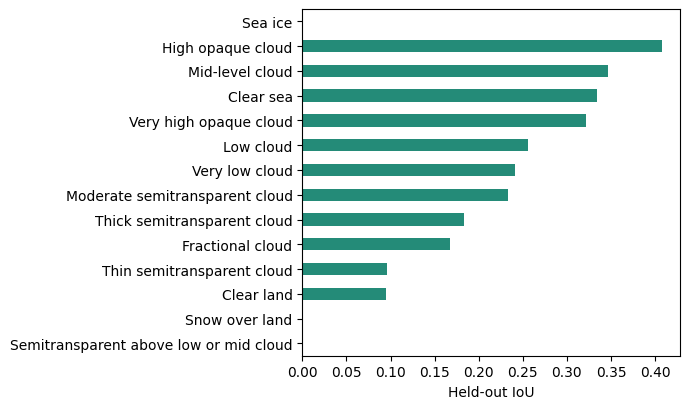

In [3]:
winner = next(m for m in models if m["model"]==report["recommended_segmentation"])
classes = pd.DataFrame(winner["per_class"]).set_index("name")
axes = classes["iou"].sort_values().plot.barh(figsize=(7,4.2),color="#248b78",xlabel="Held-out IoU",ylabel="")
axes.figure.tight_layout()
axes.figure

## Validation-only calibration and spatial errors

In [4]:
cal = winner["calibration_validation"]
pd.Series({"temperature":cal["temperature"], "ECE before":cal["before"]["ece"],"ECE after":cal["after"]["ece"], **winner["error_analysis"]})

temperature                    0.801200
ECE before                     0.055909
ECE after                      0.009274
boundary_pixels           467617.000000
boundary_error_rate            0.643283
small_cloud_pixels        220753.000000
small_cloud_error_rate         0.670867
clear_surface_pixels      122069.000000
false_cloud_rate               0.749306
dtype: float64

## Rebuild the held-out report

Run `python -m src.evaluate` to score the packaged frozen registry. Machine-readable per-class results, confusion matrices, temporal scores and figure filenames are in `experiments/comparison.json`.